# Fundamentos de Ciencia de Datos - FCEx - UNICEN

# Unidad 5: Reducción de dimensionalidad

## Clase Práctica 6: Reducción de dimensionalidad

Este Colab corresponde a la sexta clase práctica del curso Fundamentos de Ciencia de Datos, que se dicta en el 4to año de la carrera de Ingeniería de Sistemas de la Facultad de Ciencias Exactas de la UNICEN.

La clase de hoy va a centrarse en reducción de dimensionalidad. La idea central es conocer qué librerías en Python son las más populares para reducir dimensionalidad de vectores de características, cómo utilizarlas, y algunas aplicaciones copadas.


## 0 - Descarguemos algunos datos para trabajar en la clase de hoy

Vamos a descargar a nuestro viejo amigo, el dataset de regiones de Boston con sus precios de las casas, para trabajar reducción de dimensionalidad en este contexto:

In [ ]:
# instalamos el paquete para descargar archivos wget
!pip install wget

# importamos wget y las librerías que nos faltan
from wget import download
from os import path
import pandas as pd


# bajamos las casas
if not path.exists("housing_pandas.csv"):
  download("https://ignaciorlando.github.io/datasets/housing_pandas.csv")
else:
  print("No vamos a bajar el archivo de casas porque ya existe!")
# abrimos el archivo usando una función específica de pandas
raw_dataset_houses = pd.read_csv("housing_pandas.csv")
# cambiamos a CHAS para que sea booleano
raw_dataset_houses["CHAS"] = raw_dataset_houses["CHAS"].astype(bool)
# cambiamos las columnas que son porcentajes
raw_dataset_houses["ZN"] = raw_dataset_houses["ZN"] / 100
raw_dataset_houses["INDUS"] = raw_dataset_houses["INDUS"] / 100
raw_dataset_houses["AGE"] = raw_dataset_houses["AGE"] / 100
raw_dataset_houses["LSTAT"] = raw_dataset_houses["LSTAT"] / 100

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9655 sha256=7a25c2c612538962084b15b8f2970e5a43b5a7f02610c6bf57ee4435115f0cdb
  Stored in directory: /root/.cache/pip/wheels/01/46/3b/e29ffbe4ebe614ff224bad40fc6a5773a67a163251585a13a9
Successfully built wget


## 1 - Reducción de dimensionalidad

Las técnicas de reducción de dimensionalidad permiten tomar vectores de características con $n$ variables y proyectarlos en vectores de $p$ variables, con $n > p$.

Este tipo de algoritmos puede servir, por ejemplo, para estudiar visualmente la distribución de todos los datos, proyectando las $n$ features a $p=2$ y graficando las proyecciones en un espacio.

En general, los que más se usan son 3:

* Principal Component Analysis (PCA): que se usa no solamente para graficar, si no también para achicar espacios de características (y evitar la *maldición de la dimensionalidad*).

* t-SNE y UMAP: que se usan para graficar datos multidimensionales, y en algunos casos también para preprocesar datos y reducir dimensionalidad como con PCA (aunque no es recomendable, sobre todo para t-SNE, que tiene una componente de aleatoriedad que puede hacer bastante lío si no se controla; UMAP sí se está empezando a usar más).

En las próximas subsecciones vamos a usar algunos de esos algoritmos.

#### 1.1. Principal Component Analysis (PCA)

Una de las técnicas más utilizadas para reducción de dimensionalidad es el [análisis de componentes principales (Principal Component Analysis, PCA)](https://en.wikipedia.org/wiki/Principal_component_analysis).

En el ejemplo que mostramos abajo, vamos a usar PCA para poder representar los datos gráficamente. En particular, nos interesa entender si, por ejemplo, **existe alguna relación entre las características de las diferentes regiones y el precio de las casas en cada una de ellas.** Si existiera, deberíamos ver que las muestras que están cercanas en el espacio de características deberían mostrar valores similares de precios de sus viviendas, mientras que las muestras que están más distantes deberían tener diferencias más notorias.

Ahora bien, chequeemos la dimensionalidad de nuestros datos:

In [ ]:
print(raw_dataset_houses.shape)
print(raw_dataset_houses.columns)
raw_dataset_houses.info()

(506, 14)
Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MEDV'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    bool   
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: bool(1), float64(13)
memory usage: 52.0 KB


Podemos ver que tenemos 506 muestras con 14 variables o características cada una (incluyendo la del precio, que es la que nos interesa estudiar). En consecuencia, no podríamos graficar esas muestras en, por ejemplo, un scatter plot, ya que deberíamos sí o sí elegir un subconjunto de dos variables para hacerlo.

Para revertir este problema, podemos usar PCA. Mediante esta técnica, podemos proyectar a un espacio de 2 dimensiones, y usar esas proyecciones ortogonales como valores de variable para los ejes X e Y.

A continuación aplicaremos PCA sobre todas nuestras features para mapear los datos de entrenamiento a un espacio 2D, y graficar los precios de las viviendas en ese espacio de 2 (nuevas) características proyectadas de las actuales.

Veamos cómo hacerlo usando [scikit-learn](https://scikit-learn.org/stable/).  Scikit Learn (sklearn para los amigos) provee varias funcionalidades para hacer machine learning, incluyendo varias [técnicas de reducción de dimensionalidad](https://scikit-learn.org/stable/modules/decomposition.html).

Tengan en cuenta que vamos a tener que sacar 2 variables en este caso: la del precio (que es la variable que queremos estudiar en relación a las otras), y CHAS, que es una variable dicotómica, no cuantitativa, y por ende no debemos incluirla:

Antes de PCA: (506, 12)
Después de PCA: (506, 2)


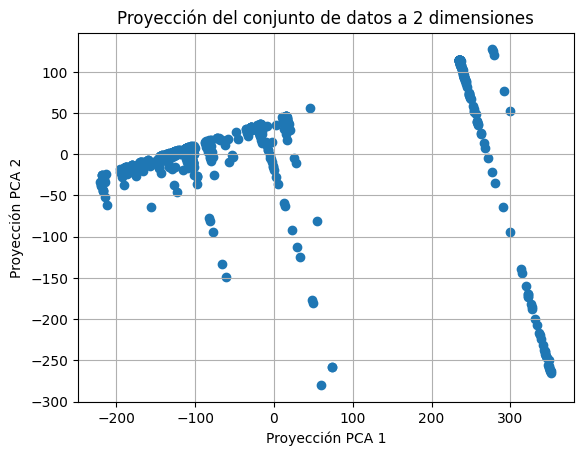

In [ ]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# sacamos la variable MEDV, que tiene el precio, y CHAS, que es dicotómica,
# para quedarnos solamente con todas las otras características
X = raw_dataset_houses.drop(['MEDV', 'CHAS'], axis=1)

# declaramos un objeto PCA que mapee n dimensions a p=2, y que además
# normalice esas features (whiten=True)
pca = PCA(n_components=2, whiten=False)
# le pedimos al objeto que se ajuste utilizando los datos (fit) y que además
# transforme los datos, para ya reducir a dos dimensiones
principalComponents = pca.fit_transform(X)
# imprimimos los tamaños antes y después
print('Antes de PCA: {}'.format(X.shape))
print('Después de PCA: {}'.format(principalComponents.shape))

# graficamos los datos. el color de cada punto representa el valor de la casa
plt.scatter(principalComponents[:,0], principalComponents[:,1])
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.show()

Vemos que con este pequeño cambio fuimos capaces ahora de proyectar todas nuestras muestras a este espacio de dos dimensiones. ¡Buenísimo!

Ahora bien, ¿se ve algo raro, no? Como que las muestras tienen una distribución extraña, hay como una recta a la izquierda y otra a la derecha... Normalmente si vemos algo así, hay algo mal que no anda bien.

El PCA busca las direcciones de máxima varianza en los datos, proyectando el espacio original en componentes ortogonales que explican la mayor cantidad posible de variabilidad.
Por eso, el PCA es sensible a la escala de las variables:
* Si una variable está medida en unidades grandes, su varianza numérica será mayor.
* El PCA interpretará eso como “más importante”, y las primeras componentes quedarán dominadas por esas variables, sin importar su relevancia real.

Estandarizar (restar la media y dividir por el desvío estándar) hace que:
* Todas las variables tengan media 0 y desvío estándar 1.
* El PCA analice covarianza normalizada (correlación) en lugar de varianza absoluta.
* Las variables contribuyan equitativamente al análisis.

Aunque no es estrictamente necesario estandarizar los valores antes de aplicar PCA, es altamente recomendable en la mayoría de los casos. La razón principal es que PCA se basa en la varianza de los datos y, si las variables tienen escalas muy diferentes, aquellas con mayor varianza (y, por lo tanto, con mayor magnitud) tendrán una influencia desproporcionada en los componentes principales.

Veamos si corríamos ese riesgo, simplemente usando un ```describe``` de Pandas:

In [ ]:
X.describe()

,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,0.113636,0.111368,0.554695,6.284634,0.685749,3.795043,9.549407,408.237154,18.455534,356.674032,0.126531
std,8.601545,0.233225,0.068604,0.115878,0.702617,0.281489,2.105710,8.707259,168.537116,2.164946,91.294864,0.071411
min,0.006320,0.000000,0.004600,0.385000,3.561000,0.029000,1.129600,1.000000,187.000000,12.600000,0.320000,0.017300
25%,0.082045,0.000000,0.051900,0.449000,5.885500,0.450250,2.100175,4.000000,279.000000,17.400000,375.377500,0.069500
50%,0.256510,0.000000,0.096900,0.538000,6.208500,0.775000,3.207450,5.000000,330.000000,19.050000,391.440000,0.113600
75%,3.677083,0.125000,0.181000,0.624000,6.623500,0.940750,5.188425,24.000000,666.000000,20.200000,396.225000,0.169550
max,88.976200,1.000000,0.277400,0.871000,8.780000,1.000000,12.126500,24.000000,711.000000,22.000000,396.900000,0.379700


Vemos que, por ejemplo, CRIM tiene un desvío muy alto (por ende, una varianza también muy alta), en relación a otras variables como ZN, INDUS o NOX. Lo mismo ocurre con RM, DIS y TAX. Claramente tenemos que estandarizar.

Para hacerlo vamos a usar ```StandardScaler``` de scikit-learn, una clase que nos permite estimar la media y desvío a partir de un conjunto de datos, y usarlas para estandarizar los datos. Tengan en cuenta que el resultado va a ser un Numpy array, por ende vamos a tener que calcular los desvíos nosotros usando Numpy, y no aprovechar el método ```describe()```:

In [ ]:
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# estandarizamos X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(np.mean(X_scaled, axis=0))
print(np.std(X_scaled, axis=0))

[-1.12338772e-16 -2.36964598e-17 -1.12338772e-16 -1.96592852e-16
 -1.08828186e-16 -9.82964259e-17 -8.42540793e-17 -1.12338772e-16
  0.00000000e+00 -4.21270397e-16 -7.44244367e-16  1.40423466e-16]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Ahora sí! Todas las features tienen la misma varianza! Cumpliendo con esta condición, podemos pasar a usar PCA normalmente:

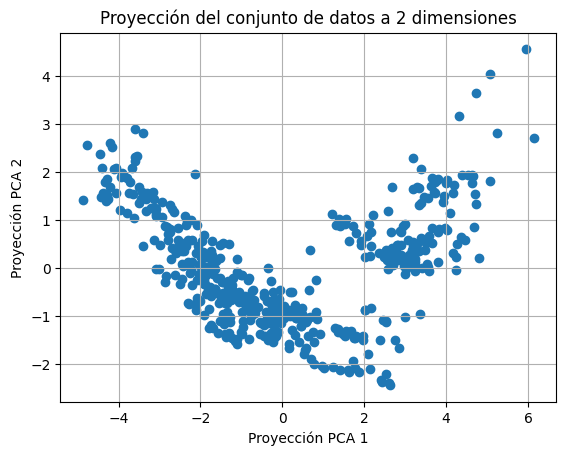

In [ ]:
# Ahora aplicamos PCA a los datos estandarizados
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
# graficamos los datos
plt.scatter(X_pca[:,0], X_pca[:,1])
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.show()

Ahora la cosa luce bastante distinta, ¿no? Se ve que hay dos grupos bien definidos de regiones, con un área de transición entre ambas. Nada que ver con lo que veíamos antes.

Ahora bien, todavía no estamos viendo cómo estas 13 características proyectadas a 2 dimensiones se comparan con el valor de las casas en cada región. La mejor forma de hacerlo, en este caso, es utilizando el color: de esta forma, podemos "pintar" cada región según el valor de las propiedades en ellas, y estudiar qué pasa. Para hacerlo, es tan simple como pasarle esa variable como color al scatter plot, y elegir un colormap:

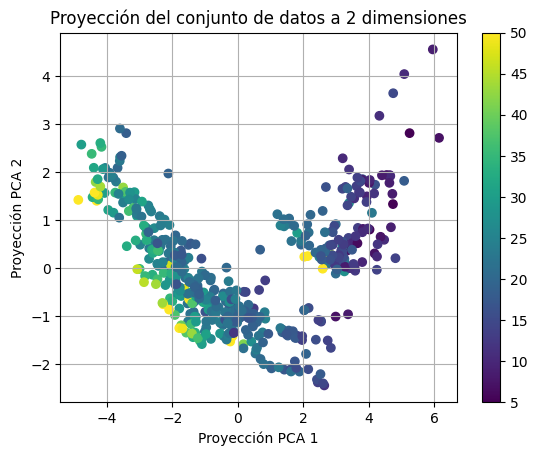

In [ ]:
# graficamos los datos. el color de cada punto representa el valor de la casa
plt.scatter(X_pca[:,0], X_pca[:,1], c=raw_dataset_houses["MEDV"], cmap='viridis')
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar()
plt.show()

Y ahora sí! Vemos con claridad que hay algo pasando en este conjunto de datos. Podemos ver, por ejemplo, que en general hay una evolución de derecha a izquierda de los precios. Esto en principio nos dice que hay algún tipo de relación entre las variables que estamos estudiando y los precios. Algunas muestras (las de las casas más caras) ocurren en diferentes lugares de este espacio proyectado, lo que podría indicar que esos precios quizá se asignen siguiendo alguna característica que no está incluida en nuestro conjunto de datos. Pero, en líneas generales, hay un comportamiento y una relación que, tal vez, podríamos explorar para intentar, por ejemplo, predecir automáticamente el valor de las casas en una región según sus características.

Pero.... spoiler alert! Eso lo vamos a hacer en la última clase práctica :)

Antes de irnos, un detalle más. Cada vez que hacemos ```fit``` (o ```fit_transform```), ocurren cambios dentro de nuestro objeto de la clase ```PCA```, actualizaciones en los atributos para reflejar el resultado del ajuste que hicimos. Si, por ejemplo, queremos consultar algunos de esos atributos, es tan simple como accederlos (previo buscar cuáles son, ¿no?). Miren todo lo que guarda PCA adentro:

In [ ]:
pca.__dict__

{'n_components': 2,
 'copy': True,
 'whiten': False,
 'svd_solver': 'auto',
 'tol': 0.0,
 'iterated_power': 'auto',
 'n_oversamples': 10,
 'power_iteration_normalizer': 'auto',
 'random_state': None,
 'n_features_in_': 12,
 '_fit_svd_solver': 'covariance_eigh',
 'mean_': array([-1.12338772e-16, -2.36964598e-17, -1.12338772e-16, -1.96592852e-16,
        -1.08828186e-16, -9.82964259e-17, -8.42540793e-17, -1.12338772e-16,
         0.00000000e+00, -4.21270397e-16, -7.44244367e-16,  1.40423466e-16]),
 'noise_variance_': np.float64(0.4539773801255545),
 'n_samples_': 506,
 'n_components_': 2,
 'components_': array([[ 0.25101944, -0.25627629,  0.34662521,  0.34277318, -0.18934428,
          0.3135926 , -0.32145202,  0.31981927,  0.33851802,  0.20507387,
         -0.20302926,  0.30982454],
        [ 0.40124935,  0.43910123, -0.10826541, -0.16538852,  0.07676264,
         -0.31549763,  0.3273196 ,  0.38437642,  0.32057097,  0.17273359,
         -0.33625146, -0.03364522]]),
 'explained_variance_

[En la documentación van a encontrar bastante sobre qué representa cada uno de esos atributos](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html#sklearn.decomposition.PCA), pero al menos un atributo está bueno que conozcan: ```explained_variance_ratio_```. Este valor representa la proporción de la varianza total del conjunto de datos original que es explicada por cada uno de los componentes principales. En otras palabras, te indica cuánta información (o varianza) de los datos originales captura cada componente principal.

Veamos lo que obtuvimos en este caso:

In [ ]:
pca.explained_variance_ratio_

array([0.5105599 , 0.11187327])


Si el valor de explained_variance_ratio_ de un componente principal es alto, significa que ese componente captura una parte significativa de la variabilidad (información) de los datos. Así que este valor es útil para determinar cuántos componentes principales necesitas retener para capturar un porcentaje deseado de la varianza total. Por ejemplo, si los primeros dos componentes principales explican el 95% de la varianza, podés reducir la dimensionalidad a esos dos componentes sin perder mucha información. En este caso, todo pareciera indicar que necesitaríamos algunas dimensiones más para calcular ese 95% de varianza.

Antes de pasar al próximo tema, quiero que veamos cómo generar un biplot en Python.

En la teoría vimos que el biplot es una representación gráfica que combina dos cosas al mismo tiempo:
1. Las observaciones (o muestras) proyectadas sobre las dos primeras componentes principales del PCA (habitualmente PC1 y PC2).
  * Recuerden siempre que cada punto representa una muestra en el nuevo espacio reducido.
  * Recuerden también que la distancia entre puntos refleja "su similitud": si dos puntos están cerca, sus perfiles de variables son parecidos.
2. Las variables originales, representadas como vectores (flechas) en ese mismo plano.
  * Cada flecha indica cómo una variable contribuye a esas dos componentes.
  * La dirección y longitud de la flecha muestran la correlación entre la variable y las componentes.

Interpretarlo puede parecer difícil, pero no es tanto. Imaginá que el PCA transformó tus variables originales en dos ejes principales (PC1 y PC2) (en más no tendría sentido, no podríamos graficar el espacio). El biplot a vos te muestra:
1. Los puntos (muestras): su posición según las nuevas coordenadas.
2. Las flechas (variables): hacia dónde “empuja” cada variable el conjunto de datos.

Entonces:
* Flechas "largas" van a representar variables con alta varianza explicada (por ende, que influyen mucho en esas componentes).
* Flechas cercanas entre sí van a representar variables positivamente correlacionadas (es decir, si el ángulo entre las flechas es bajo, significa que hay un vínculo lineal fuerte entre ambas).
* Flechas opuestas (tipo, a 180° una de la otra, o recontra separadas por un ángulo grande) significa que esas variables tienen correlación negativa.
* Puntos que quedan en la dirección de una flecha: significa que esas muestras tienen valores altos en esa variable.

Me vas a decir: Nacho, qué ganas de complicarla, ¿para qué un biplot? Bueno, yo tampoco los uso mucho, pero la verdad es que en un biplot podés ver a la vez:
* Cómo se agrupan las muestras según su similitud
* Qué variables explican esas agrupaciones
* Cómo se relacionan las variables entre sí.
Por eso se lo suele usar cuando estás explorando datos, por ejemplo, para entender de un saque esas relaciones que se te hubieran escapado de otra forma.

Bueno, vamos a los bifes. Para generar un biplot vamos a necesitar una librería externa, [Yellowbrick](https://www.scikit-yb.org/en/latest/), una biblioteca de Python que incluye varias implementaciones de gráficas complejas que se usan con frecuencia en machine learning y ciencia de datos.

Para instalarla es muy fácil:

In [ ]:
!pip install yellowbrick

Ahora que ya la tenemos instalada, vamos a aplicarla sobre nuestros datos:

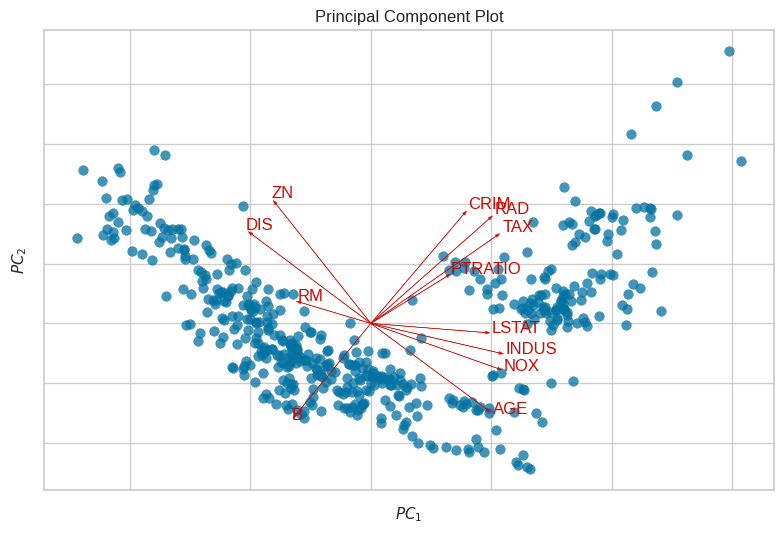

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [ ]:
from yellowbrick.features import PCA as PcaViz

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
    scale=True,          # le vamos a pedir que estandarice (si le pasáramos datos estandarizados esto va en false)
    proj_features=True,  # le pedimos que dibuje las proyecciones de la features originales
    projection=2,        # le pedimos dos proyecciones
)
# lo aplicamos sobre los datos originales
viz.fit_transform(X)
# y pedimos que se grafique
viz.show()

Analicemos algunas relaciones:

* **NOX (concentración de óxidos de nitrógeno) e INDUS (proporción de industrias)** tienen un ángulo muy pequeño una respecto de la otra. Esto a priori nos dice que tienen una correlación alta, lo cuál tiene sentido, teniendo en cuenta que las zonas industriales tienen normalmente mayor contaminación.

* Las flechas de **RM (número de habitaciones) y DIS (distancia a centros de empleo)** apuntan en dirección opuesta a LSTAT (proporción de población de bajo status) y NOX (concentración de óxidos de nitrógeno). Eso indica que los barrios con casas más grandes y alejados del centro suelen tener menos contaminación y menor proporción de hogares de bajo estatus.

* Si pensamos las componentes principales en cuadrantes, vamos a ver que **AGE (porcentaje de casas viejas ocupadas), INDUS (proporción de zonas industriales), TAX (tasas impositivas), RAD (acceso a autopistas) y CRIM (tasa de criminalidad)** están agrupadas en valores altos de PC1. Esto implica que esta variable esté reflejando zonas de mayor antigüedad de viviendas, con más proporción de terrenos industriales, más impuestos y autopistas y mayor criminalidad, lo que pareciera a priori definir aspectos vinculados con urbanización densa o degradada.

Bueno, podemos hacer muchísimas más de estas, ¿no? Pero se las dejo a uds.

### 1.2. t-distributed Stochastic Neighbor Embedding (t-SNE)

[t-SNE](https://en.wikipedia.org/wiki/T-distributed_stochastic_neighbor_embedding) es, sobre todo, una herramienta de visualización para datos de alta dimensionalidad. Sí, es una técnica de reducción de dimensionalidad, pero te la vas a cruzar sobre todo cuando intentes explorar la estructura de datos complejos en espacios de alta dimensionalidad. Es útil, por ejemplo, si querés chusmear cómo se agrupan los datos o cómo se relacionan entre sí en un espacio de menor dimensión, superponiendo arriba, por ejemplo, resultados de un algoritmo de clustering.

Me podés decir: che, loco, ¿por qué me voy a tirar a usar t-SNE si ya sé PCA, que hace lo mismo? Bueno, viejx, no te pongas así, jajajaja. La principal diferencia es que PCA es lineal, y t-SNE es no lineal.

A ver qué significa esto. Cuando decimos que PCA es un método lineal, nos referimos a que se basa en la transformación lineal de los datos para encontrar las direcciones de máxima varianza. Es decir, PCA encuentra combinaciones lineales de las variables originales que maximicen la varianza en el conjunto de datos.

Debido a que PCA solo considera relaciones lineales, no va a poder captar patrones no lineales complejos que puedan estar presentes en los datos. Por ejemplo, si las relaciones entre las variables no pueden ser descritas mediante combinaciones lineales (como en datos donde las relaciones sean curvas o más complejas), PCA no será capaz de capturar esa estructura.

Peeeeeeto t-SNE sí. t-SNE es capaz de capturar relaciones no lineales en los datos. Así que, si tiraste un PCA, te aseguraste de haber hecho todo bien, y aún así no pudiste ver nada útil, te conviene siempre hacerle un tiro a t-SNE, y verificar si podés encontrar algo.

A continuación vamos a simplemente generar una representación t-SNE para los datos con los que estamos trabajando. Tengan en cuenta que usaremos la implementación de ```sklearn```, que aunque parezca muy rápida para las pocas muestras que tenemos, tarda banda cuando la cantidad de muestras es muy grande. Si necesitan algo más eficiente, les recomiendo [esta implementación](https://github.com/CannyLab/tsne-cuda) que usa GPU.

Before t-SNE: (506, 12)
After t-SNE: (506, 2)


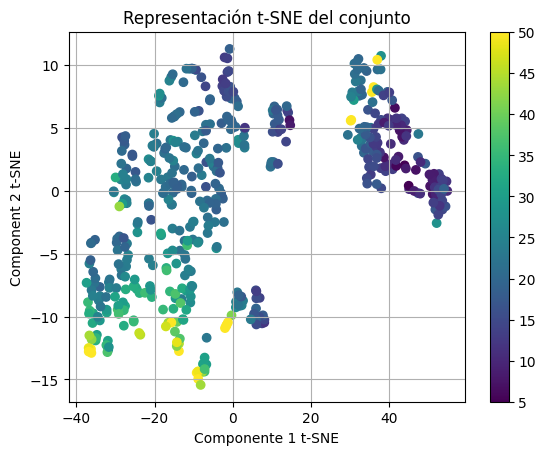

In [ ]:
# importamos el t-SNE
from sklearn.manifold import TSNE

# creamos el objeto, lo fitteamos en nuestros datos y lo aplicamos sobre esos mismos
#X_tsne = TSNE(n_components=2).fit_transform(X_scaled) # sin random state
X_tsne = TSNE(n_components=2, random_state=10).fit_transform(X_scaled)  # con random state
# imprimimos los tamaños antes y después
print('Before t-SNE: {}'.format(X_scaled.shape))
print('After t-SNE: {}'.format(X_tsne.shape))

# graficamos los datos, el color de cada punto representa el valor de la casa
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=raw_dataset_houses["MEDV"], cmap='viridis')
plt.grid(True)
plt.xlabel('Componente 1 t-SNE')
plt.ylabel('Component 2 t-SNE')
plt.title('Representación t-SNE del conjunto')
plt.colorbar()
plt.show()

Si hacemos varias corridas vamos a observar que los resultados son diferentes. Esto es porque el proceso de inferencia del embedding que estamos graficando es estocástico, lo que implica que hay una aleatoriedad que no podemos controlar. Si usamos una variable ```random_state``` vamos a obtener siempre la misma proyección. Recomendamos eso cuando estén laburando en algún paper.

Acá seguimos viendo que hay una relación entre los precios y las características, pero que la gráfica no es la misma. Y es de esperar, porque lo que está ocurriendo internamente es distinto.

Ahora bien. [Si chequean t-SNE en la documentación](https://scikit-learn.org/dev/modules/generated/sklearn.manifold.TSNE.html) van a ver que está llena de parámetros. Elegirlos es un lío, realmente. Les recomiendo [esta página](https://distill.pub/2016/misread-tsne/) para ver cómo los más leves cambios pueden producir salidas rarísimas.

### 1.3. Uniform Manifold Approximation and Projection (UMAP)

[UMAP](https://towardsdatascience.com/how-exactly-umap-works-13e3040e1668) es otro algoritmo alternativo a t-SNE para generar visualizaciones de datos con alta dimensionalidad. Es algo más reciente y se ha puesto de moda últimamente, aunque los resultados de uno y otro suelen ser muy compatibles. Fue introducida como una mejora respecto a otras técnicas como t-SNE, especialmente cuando se busca un método más rápido y que preserve mejor las relaciones entre puntos lejanos y cercanos. También es no lineal, así que es otra herramienta para que tengas en cuenta si te falló PCA.

Al ser tan nuevo, todavía no está implementado en ```sklearn```, con lo que vamos a tener que instalar [una librería aparte que lo implementa](https://umap-learn.readthedocs.io/en/latest/index.html).

In [ ]:
!pip install umap-learn

Para utilizarlo no tenemos más que importar la clase, crear una instancia, fittearla y aplicarla sobre nuestros datos como hicimos antes con t-SNE:

Antes de UMAP: (506, 12)
Después de UMAP: (506, 2)


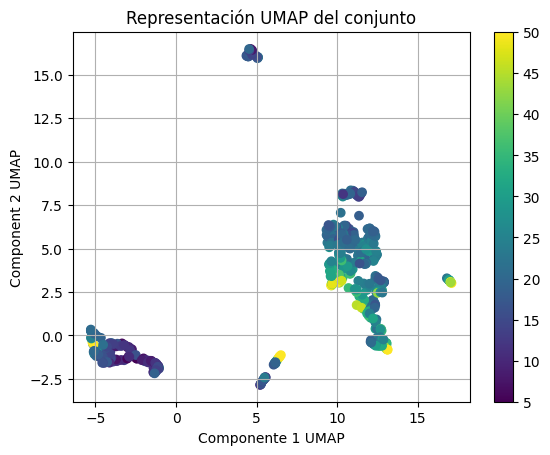

In [ ]:
# importamos umap
from umap import UMAP

# creamos el objeto, lo fitteamos en nuestros datos y lo aplicamos sobre esos mismos
X_umap = UMAP(n_components=2).fit_transform(X_scaled)
# imprimimos los tamaños antes y después
print('Antes de UMAP: {}'.format(X_scaled.shape))
print('Después de UMAP: {}'.format(X_umap.shape))

# graficamos los datos, el color de cada punto representa el valor de la casa
plt.scatter(X_umap[:,0], X_umap[:,1], c=raw_dataset_houses["MEDV"], cmap='viridis')
plt.grid(True)
plt.xlabel('Componente 1 UMAP')
plt.ylabel('Component 2 UMAP')
plt.title('Representación UMAP del conjunto')
plt.colorbar()
plt.show()

El gráfico resultante no se ve muy atractivo, ¿no? Peeeeero, vemos grupos, vemos transiciones, vemos que algo está pasando.

¿Por qué se ve tan feo? Bueno, porque UMAP es ideal cuando trabajás con datos que tienen estructuras no lineales complejas. Es útil para identificar agrupamientos o patrones en los datos de alta dimensión que no son evidentes, y que son no lineales. Acá sabemos que hay linealidad, así que estamos medio fritos.


Bueno, ¿les gustó? Les cuento que son las 20:14 del día anterior a la clase, y que anoche me acosté a las 3:51 de la mañana, porque tenía un deadline, y que estoy medio dormido. Si encuentran un bug, me chiflan! Nos vemos la próxima!